In [1]:
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
import time
import sys
import importlib
from pathlib import Path

for project_root in (Path.cwd(), Path.cwd().parent):
    if (project_root / 'binary_sync').is_dir():
        sys.path.insert(0, str(project_root))
        break

# Clear previously imported project modules so notebook cells use current source.
for module_name in list(sys.modules):
    if module_name == 'binary_sync' or module_name.startswith('binary_sync.'):
        del sys.modules[module_name]
importlib.invalidate_caches()

from matplotlib.lines import Line2D
from binary_sync.model import sample_instance, Graph
from binary_sync.bp import bp_corr2
from binary_sync.spectral import spectral_corr2
from binary_sync.low_degree import low_degree_corr2 as low_degree_corr
from binary_sync.low_degree import low_degree_weights as compute_low_degree_weights, print_low_degree_weights
from binary_sync.percolation import estimate_percolation_bound
from binary_sync.reporting import format_estimate
from binary_sync.exact_corr_sp import sp_corr2
from binary_sync.acyclic_BP import acyclic_bp_corr2

In [2]:
def test_small_graph(p: float = 0.2) -> Graph:
    """
    Construct the 6-vertex, 9-edge graph

        E = {
            (1,2), (1,3), (1,4), (1,5),
            (2,3), (2,4), (2,6),
            (3,5), (3,6)
        }.

    Every edge has crossover probability p.
    """
    G = Graph()

    edges = [
        (1, 2),
        (1, 3),
        (1, 5),
        (2, 4),
        (2, 6),
        (2, 5),
        (3, 4)
    ]

    for u, v in edges:
        G.add_edge(u, v, p)

    return G


In [3]:
def draw_graph(
    graph,
    source,
    target,
    ax=None,
    seed=0,
    title=None,
    positions=None,
):
    if source not in graph.nodes:
        raise ValueError("The source is not in the graph.")

    if target not in graph.nodes:
        raise ValueError("The target is not in the graph.")

    if ax is None:
        _, ax = plt.subplots(figsize=(5, 4))

    nx_graph = nx.MultiGraph()
    nx_graph.add_nodes_from(graph.nodes)

    for edge_id, edge in enumerate(graph.edges):
        nx_graph.add_edge(edge.u, edge.v, key=edge_id)

    if positions is None:
        positions = nx.spring_layout(nx_graph, seed=seed)

    ordinary_nodes = [
        node
        for node in graph.nodes
        if node not in {source, target}
    ]

    nx.draw_networkx_edges(
        nx_graph,
        positions,
        ax=ax,
        width=1.8,
        edge_color="gray",
    )

    nx.draw_networkx_nodes(
        nx_graph,
        positions,
        nodelist=ordinary_nodes,
        ax=ax,
        node_size=700,
        node_color="lightblue",
        edgecolors="black",
    )

    nx.draw_networkx_nodes(
        nx_graph,
        positions,
        nodelist=[source],
        ax=ax,
        node_size=850,
        node_color="mediumseagreen",
        edgecolors="black",
        linewidths=2,
    )

    nx.draw_networkx_nodes(
        nx_graph,
        positions,
        nodelist=[target],
        ax=ax,
        node_size=850,
        node_color="darkorange",
        edgecolors="black",
        linewidths=2,
    )



    node_labels = {
        node: ("s" if node == source else "t" if node == target else str(node))
        for node in graph.nodes
    }

    nx.draw_networkx_labels(
        nx_graph,
        positions,
        labels=node_labels,
        ax=ax,
        font_size=10,
    )

    # legend_handles = [
    #     Line2D(
    #         [0],
    #         [0],
    #         marker="o",
    #         color="none",
    #         markerfacecolor="mediumseagreen",
    #         markeredgecolor="black",
    #         markersize=11,
    #         label=f"Source: {source}",
    #     ),
    #     Line2D(
    #         [0],
    #         [0],
    #         marker="o",
    #         color="none",
    #         markerfacecolor="darkorange",
    #         markeredgecolor="black",
    #         markersize=11,
    #         label=f"Sink: {target}",
    #     ),
    # ]

    # ax.legend(
    #     handles=legend_handles,
    #     loc="best",
    #     frameon=False,
    # )

    if title is not None:
        ax.set_title(title)

    ax.set_axis_off()
    return ax

<Axes: >

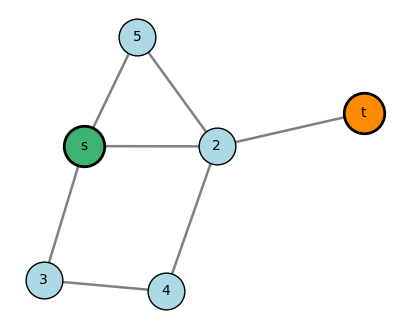

In [4]:
example = test_small_graph(0.2)
s, t = 1, 6
draw_graph(example, s, t)

In [5]:
result_low_degree = low_degree_corr(example, 7, s, t)
result_spectral = spectral_corr2(example, s, t, alg="naive", n_samples=10000, seed=3)
print(f"Low-degree: {format_estimate(result_low_degree)}")
print(f"Spectral: {format_estimate(result_spectral['corr2'])}")

Low-degree: estimate=0.156570, standard error=0.000000, 95% CI=[0.156570, 0.156570]
Spectral: estimate=0.109693, standard error=0.000000, 95% CI=[0.109693, 0.109693]


In [6]:
result_acyclic_sp = acyclic_bp_corr2(example, s, t, n_samples=50000)
print(f"Acyclic BP: {format_estimate(result_acyclic_sp['corr2'], result_acyclic_sp['standard error'])}")

Acyclic BP: estimate=0.150080, standard error=0.003089, 95% CI=[0.144025, 0.156136]


In [7]:
def make_parallel_branch_graph(m=3, n=3, p=0.1):
    graph = Graph()
    observations = []
    positions = {
        "s": (0, 0),
        "t": (8, 0),
        "a": (4, -3.5),
    }

    # The displayed observation on (s, a) is -1.
    graph.add_edge("s", "a", p)
    observations.append(-1)

    # Paths s -- c_i -- d_i -- t.
    top_heights = np.linspace(2.5, 0.5, m)

    for i, height in enumerate(top_heights, start=1):
        c = f"c_{i}"
        d = f"d_{i}"

        positions[c] = (3, height)
        positions[d] = (5, height)

        graph.add_edge("s", c, p)
        observations.append(1)

        graph.add_edge(c, d, p)
        observations.append(1)

        graph.add_edge(d, "t", p)
        observations.append(1)

    # Paths a -- b_j -- t.
    a_position = np.array(positions["a"], dtype=float)
    t_position = np.array(positions["t"], dtype=float)

    offsets = np.linspace(0.8, -0.8, n)

    for j, offset in enumerate(offsets, start=1):
        b = f"b_{j}"
        fraction = j / (n + 1)

        base_position = (
            (1 - fraction) * a_position
            + fraction * t_position
        )

        positions[b] = tuple(
            base_position + np.array([0, offset])
        )

        graph.add_edge("a", b, p)
        observations.append(1)

        graph.add_edge(b, "t", p)
        observations.append(1)

    return (
        graph,
        "s",
        "t",
        np.array(observations, dtype=int),
        positions,
    )
sp_graph, s, t, observations, positions = make_parallel_branch_graph(m=5, n=5, p=0.2)

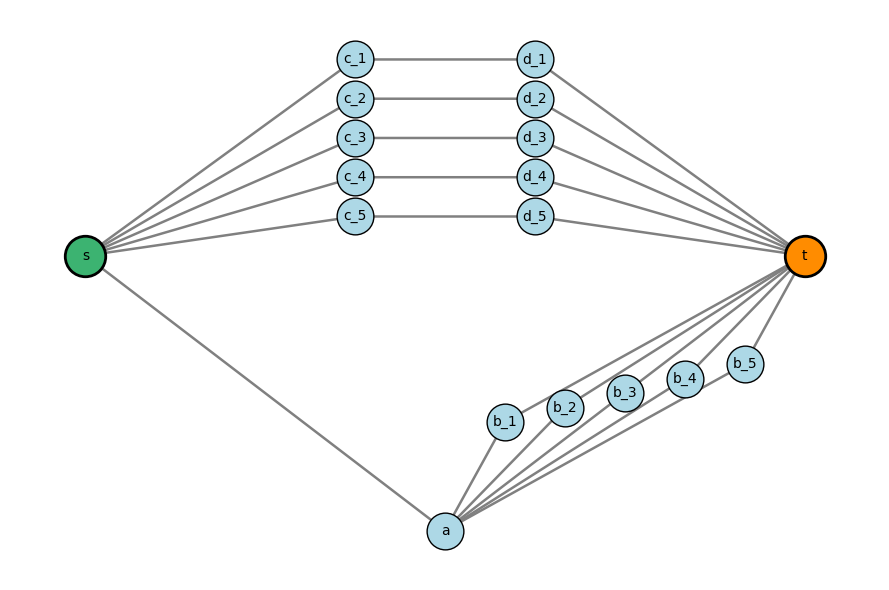

In [53]:
fig, ax = plt.subplots(figsize=(9, 6))

draw_graph(
    sp_graph,
    source=s,
    target=t,
    positions=positions,
    ax=ax,
    # title=r"Parallel-branch graph: $m=n=3$",
)

plt.tight_layout()
plt.show()

In [54]:
result_low_degree = low_degree_corr(sp_graph, 4, s, t)
result_spectral = spectral_corr2(sp_graph, s, t, alg="naive", n_samples=10000, seed=3)
print(f"Low-degree: {format_estimate(result_low_degree)}")
print(f"Spectral: {format_estimate(result_spectral['corr2'])}")

Low-degree: estimate=0.298846, standard error=0.000000, 95% CI=[0.298846, 0.298846]
Spectral: estimate=0.214554, standard error=0.000000, 95% CI=[0.214554, 0.214554]


In [56]:
result_acyclic_bp = acyclic_bp_corr2(sp_graph, s, t, n_samples=50000)
print(f"Acyclic BP: {format_estimate(result_acyclic_bp['corr2'], result_acyclic_bp['standard error'])}")

Acyclic BP: estimate=0.287644, standard error=0.003310, 95% CI=[0.281157, 0.294131]


In [12]:
def make_two_cluster_graph(k=4, p=0.2):
    G = Graph()

    left = [f"a{0}"] + [f"a{i}" for i in range(1, k)]
    right = [f"b{0}"] + [f"b{i}" for i in range(1, 2 * k)]

    # Dense left cluster.
    for i in range(k):
        for j in range(i + 1, k):
            G.add_edge(left[i], left[j], p)

    # Dense right cluster.
    for i in range(2 * k):
        for j in range(i + 1, 2 * k):
            G.add_edge(right[i], right[j], p)

    # Sparse cut between clusters.
    for i in range(1, k):
        G.add_edge(f"a{i}", f"b{i}", p)

    s, t = "b4", "b5"

    return G, s, t

<Axes: title={'center': 'Two-cluster graph'}>

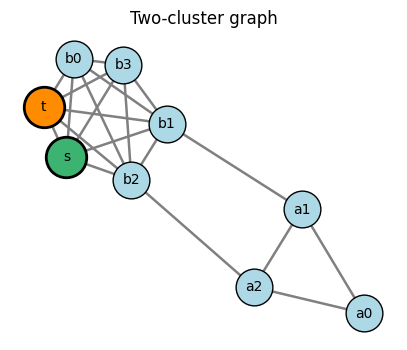

In [13]:
two_cluster_graph, s, t = make_two_cluster_graph(k=3, p=0.2)
draw_graph(two_cluster_graph, s, t, title="Two-cluster graph")

In [14]:
result_low_degree = low_degree_corr(two_cluster_graph, 5, s, t)
result_spectral = spectral_corr2(two_cluster_graph, s, t, alg="naive", n_samples=10000, seed=3)
print(f"Low-degree: {format_estimate(result_low_degree)}")
print(f"Spectral: {format_estimate(result_spectral['corr2'])}")

Low-degree: estimate=0.606806, standard error=0.000000, 95% CI=[0.606806, 0.606806]
Spectral: estimate=0.532900, standard error=0.000000, 95% CI=[0.532900, 0.532900]


In [15]:
result_acyclic_sp = acyclic_bp_corr2(two_cluster_graph, s, t, n_samples=50000)
print(f"Acyclic BP: {format_estimate(result_acyclic_sp['corr2'], result_acyclic_sp['standard error'])}")

Acyclic BP: estimate=0.415599, standard error=0.002293, 95% CI=[0.411104, 0.420093]
